# Credit Card Fraud Detection — PySpark + Spark SQL Edition

Reworked from the original pandas/sklearn notebook. What changed:

- **Ingestion, schema/EDA, feature engineering, and the train/val/test split**
  now run on Spark (DataFrame API + Spark SQL), so this scales past a single
  machine once the transaction log grows past what fits in memory.
- **PSI drift monitoring** runs as Spark SQL and now emits an explicit
  `drift_flag` boolean per feature (and for the model's output score),
  not just a printed status string.
- **Model training** (SMOTE + Logistic Regression / Random Forest / XGBoost)
  stays scikit-learn — see `src/train.py` docstring for why that boundary
  is where it is.
- **Serving** is a FastAPI app (`src/api/main.py`) with `/predict`, `/drift`,
  and `/health`, backed by the artifacts this notebook produces.

This notebook is a thin narrative layer over `src/`; it imports and runs
the same modules the CLI / API use, so nothing here is reimplemented.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..").resolve() / "src"))

DATA_PATH = "../data/creditcard_sample.csv"  # point at the real creditcard.csv for a full run
ARTIFACTS_DIR = Path("../artifacts")

pd.set_option("display.max_columns", 50)

## 1 · Spark session + ingestion

In [2]:
from spark_session import get_spark, quiet_spark
from spark_etl import load_raw, schema_and_null_check

spark = get_spark("fraud-notebook")
quiet_spark(spark)

raw = load_raw(spark, DATA_PATH)
clean = schema_and_null_check(raw)
clean.limit(5).toPandas()

26/09/24 23:38:49 WARN Utils: Your hostname, vm resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/09/24 23:38:49 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/09/24 23:38:49 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Rows: 20,000 | Null cells: 0 | Duplicate rows dropped: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,77.678106,0.978155,-0.107434,1.615729,-0.323274,1.145177,0.562970,0.198373,-2.350306,0.126658,-0.470975,0.177197,-0.053662,0.257193,-0.273000,0.526809,-0.843825,-0.649593,0.579120,0.372270,1.017044,0.409480,-0.689740,2.250352,0.345349,0.282949,0.761703,1.178003,-0.263781,10.84,0
1,110.990079,-0.118729,-0.909333,0.097593,-0.905152,-2.020438,-0.310685,-0.180361,1.005299,-0.640983,0.832362,-0.017534,0.529167,-1.136951,1.856551,0.724316,0.634255,1.169722,0.417682,-0.372843,0.341213,-1.345887,0.021368,0.311153,2.447965,-0.340857,0.887591,-0.433735,1.126900,39.59,0
2,222.902402,-0.008297,1.307734,0.278843,-0.438467,-0.238728,0.202601,-1.695233,0.435099,0.937436,1.271827,0.934962,0.601941,0.062541,-0.913924,-1.283423,0.315648,0.065959,0.380944,-1.440479,0.540997,1.553364,0.322232,-0.221754,0.424778,-0.498679,0.176274,0.210166,0.964782,41.90,0
3,319.586169,-1.322168,-0.982298,-0.034952,0.323839,0.625523,-0.752297,0.842022,1.629319,0.476489,-0.174888,-1.658413,-0.190492,-2.603026,0.438876,-0.943061,0.701694,-0.263339,-0.530328,-1.643039,1.405653,-0.580500,0.695071,-0.365826,-1.627845,1.147816,0.130576,-1.007203,0.707343,9.34,0
4,405.491982,-0.570011,-0.932094,1.115260,-0.947840,-1.214452,1.482656,1.326187,0.639911,0.154103,-0.393788,-0.459399,-0.835113,-0.269853,-0.815918,0.383134,-0.946467,-0.418857,0.369425,-0.891505,0.676064,-2.942664,-1.068489,0.695891,0.119696,1.542092,-1.949611,-0.360745,1.021600,163.45,0


## 2 · EDA via Spark SQL

,Class,n,pct
0,0,19940,99.7000
1,1,60,0.3000


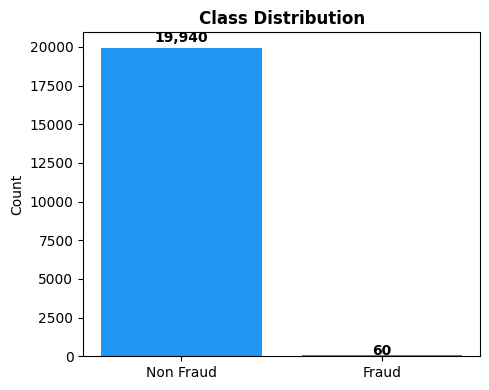

,Class,n,mean_amount,median_amount,stddev_amount,max_amount
0,0,19940,61.44,20.01,174.03,13650.14
1,1,60,50.16,21.37,88.13,490.23


In [3]:
from spark_etl import class_distribution, amount_stats_by_class

class_dist_pd = class_distribution(clean).toPandas()
display(class_dist_pd)

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Non Fraud", "Fraud"], class_dist_pd["n"], color=["#2196F3", "#F44336"])
ax.set_title("Class Distribution", fontweight="bold")
ax.set_ylabel("Count")
for i, v in enumerate(class_dist_pd["n"]):
    ax.text(i, v * 1.02, f"{v:,}", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

amount_stats_by_class(clean).toPandas()

## 3 · Feature engineering (Spark SQL time/amount transforms + window-based velocity)

Total columns after feature engineering: 40



[Stage 44:>                                                         (0 + 1) / 1]



/tmp/ipykernel_4427/3744133815.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(corr_pd["feature"], rotation=45, ha="right")


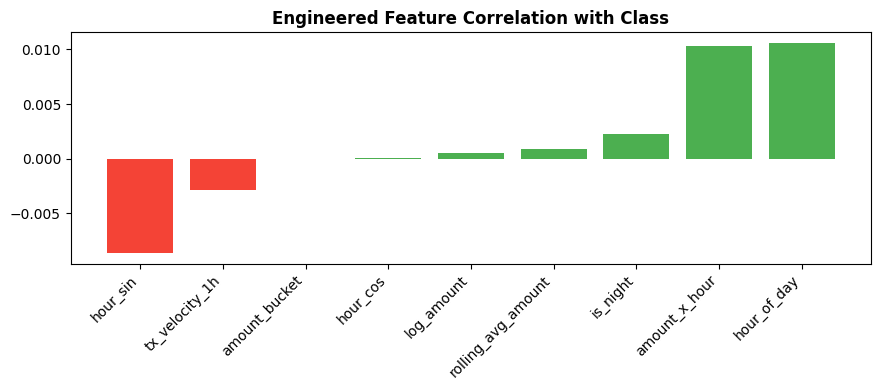

In [4]:
from spark_etl import add_features, engineered_feature_correlations, ENGINEERED_FEATURES

featurized = add_features(clean)
print(f"Total columns after feature engineering: {len(featurized.columns)}")

corr_pd = engineered_feature_correlations(featurized).toPandas()
fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#F44336" if c < 0 else "#4CAF50" for c in corr_pd["corr_with_class"]]
ax.bar(corr_pd["feature"], corr_pd["corr_with_class"], color=colors)
ax.set_title("Engineered Feature Correlation with Class", fontweight="bold")
ax.set_xticklabels(corr_pd["feature"], rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 4 · Chronological split (Spark SQL window, not `.iloc`)

In [5]:
from spark_etl import chronological_split

split = chronological_split(featurized)
print(f"Train: {split.train.count():,}  Val: {split.val.count():,}  Test: {split.test.count():,}")
spark.stop()  # ETL is done; train.py opens its own session for the run below

Train: 14,000  Val: 3,000  Test: 3,000


## 5 · Train models + generate the PSI drift report

`train.py` re-runs the Spark ETL above end-to-end (so this cell is
self-contained), collects the engineered features to pandas, applies
SMOTE + scaling, trains Logistic Regression / Random Forest / XGBoost,
picks the best model by test PR-AUC, computes the Spark SQL PSI drift
report (val = reference, test = current), and writes everything to
`../artifacts/`.

In [6]:
import train
train.main(DATA_PATH)

== Spark ETL ==


Rows: 20,000 | Null cells: 0 | Duplicate rows dropped: 0



== PSI drift report (val=reference vs test=current) ==



[Stage 61:>                                                         (0 + 1) / 1]



+------------------+---------+----------+------+
|feature           |psi      |drift_flag|status|
+------------------+---------+----------+------+
|hour_cos          |22.239179|true      |DRIFT |
|Time              |19.609559|true      |DRIFT |
|hour_of_day       |19.609559|true      |DRIFT |
|hour_sin          |5.849631 |true      |DRIFT |
|tx_velocity_1h    |1.865811 |true      |DRIFT |
|amount_x_hour     |0.997187 |true      |DRIFT |
|rolling_avg_amount|0.510292 |true      |DRIFT |
|Amount            |0.044437 |false     |OK    |
|V15               |0.025999 |false     |OK    |
|V12               |0.023262 |false     |OK    |
|V27               |0.022961 |false     |OK    |
|V21               |0.022839 |false     |OK    |
|V16               |0.022829 |false     |OK    |
|V11               |0.021826 |false     |OK    |
|V10               |0.016099 |false     |OK    |
|V3                |0.015674 |false     |OK    |
|V7                |0.014551 |false     |OK    |
|V4                |

...

[XGBoost] trained in 0.8s

== Threshold tuning on validation set ==


Logistic Regression    optimal threshold=1.0000  val F1=0.4444
Random Forest          optimal threshold=0.1650  val F1=1.0000


XGBoost                optimal threshold=0.1179  val F1=1.0000

== Final test-set evaluation ==
{'model': 'Logistic Regression', 'threshold': 1.0, 'roc_auc': 0.3664, 'pr_auc': 0.026, 'f1': 0.0, 'precision': 0.0, 'recall': 0.0, 'tp': 0, 'fp': 0, 'fn': 12, 'tn': 2988, 'net_savings_usd': 0.0}
{'model': 'Random Forest', 'threshold': 0.165, 'roc_auc': 1.0, 'pr_auc': 1.0, 'f1': 1.0, 'precision': 1.0, 'recall': 1.0, 'tp': 12, 'fp': 0, 'fn': 0, 'tn': 2988, 'net_savings_usd': 1440.0}
{'model': 'XGBoost', 'threshold': 0.1179, 'roc_auc': 1.0, 'pr_auc': 1.0, 'f1': 0.96, 'precision': 0.9231, 'recall': 1.0, 'tp': 12, 'fp': 1, 'fn': 0, 'tn': 2987, 'net_savings_usd': 1435.0}

Best model by test PR-AUC: Random Forest (threshold=0.1650)

== Score-level PSI (val vs test, best model) ==



[Stage 0:>                                                          (0 + 1) / 1]



{'metric': 'fraud_probability', 'psi': 0.030297, 'drift_flag': False, 'status': 'OK', 'watch_threshold': 0.1, 'drift_threshold': 0.25}

== Saving artifacts ==
Artifacts written to /home/claude/fraud_detection_spark/artifacts/


## 6 · Results

In [7]:
test_results = json.loads((ARTIFACTS_DIR / "test_results.json").read_text())
pd.DataFrame(test_results).set_index("model")[
    ["threshold", "roc_auc", "pr_auc", "f1", "precision", "recall", "tp", "fp", "fn", "net_savings_usd"]
]

,threshold,roc_auc,pr_auc,f1,precision,recall,tp,fp,fn,net_savings_usd
model,,,,,,,,,,
Logistic Regression,1.0000,0.3664,0.026,0.00,0.0000,0.0,0,0,12,0.0
Random Forest,0.1650,1.0000,1.000,1.00,1.0000,1.0,12,0,0,1440.0
XGBoost,0.1179,1.0000,1.000,0.96,0.9231,1.0,12,1,0,1435.0


## 7 · PSI drift report — feature-level `drift_flag`

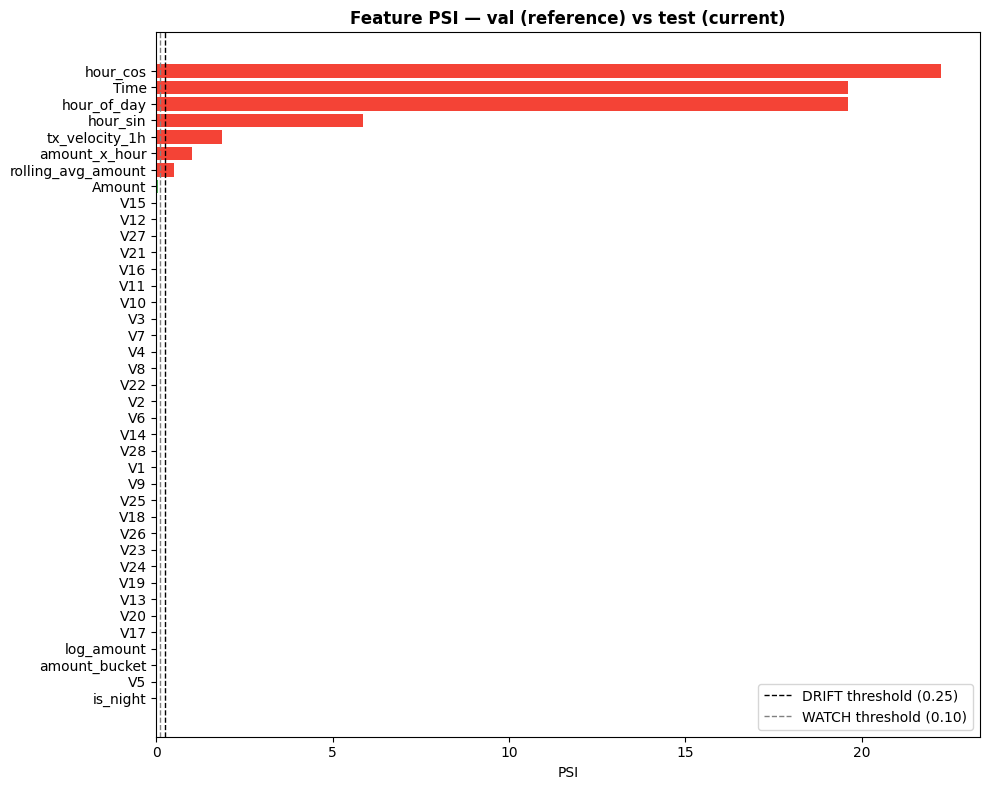

Features flagged DRIFT: 7  |  WATCH: 0
Score-level drift (model output): {'metric': 'fraud_probability', 'psi': 0.030297, 'drift_flag': False, 'status': 'OK', 'watch_threshold': 0.1, 'drift_threshold': 0.25}


,feature,psi,drift_flag,status
0,hour_cos,22.239179,True,DRIFT
1,Time,19.609559,True,DRIFT
2,hour_of_day,19.609559,True,DRIFT
3,hour_sin,5.849631,True,DRIFT
4,tx_velocity_1h,1.865811,True,DRIFT
5,amount_x_hour,0.997187,True,DRIFT
6,rolling_avg_amount,0.510292,True,DRIFT
7,Amount,0.044437,False,OK
8,V15,0.025999,False,OK
9,V12,0.023262,False,OK


In [8]:
drift_report = json.loads((ARTIFACTS_DIR / "drift_report.json").read_text())
drift_pd = pd.DataFrame(drift_report["feature_drift"]).sort_values("psi", ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
color_map = {"DRIFT": "#F44336", "WATCH": "#FF9800", "OK": "#4CAF50"}
ax.barh(drift_pd["feature"][::-1], drift_pd["psi"][::-1],
        color=[color_map[s] for s in drift_pd["status"][::-1]])
ax.axvline(0.25, color="black", ls="--", lw=1, label="DRIFT threshold (0.25)")
ax.axvline(0.10, color="gray", ls="--", lw=1, label="WATCH threshold (0.10)")
ax.set_xlabel("PSI"); ax.set_title("Feature PSI — val (reference) vs test (current)", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Features flagged DRIFT: {drift_report['n_features_drift']}  |  WATCH: {drift_report['n_features_watch']}")
print("Score-level drift (model output):", drift_report["score_drift"])
drift_pd.head(10)

Note: `Time`/`hour_of_day`/`hour_cos`/`hour_sin` show up as DRIFT here
because the reference (val) and current (test) windows are consecutive,
non-overlapping chronological slices of a 2-day dataset — a real
time-of-day shift, not a bug. It's a useful sanity check that the PSI
implementation is sensitive to genuine distribution shifts; in production
this feature's PSI would be interpreted alongside a wall-clock day-of-week
baseline rather than flagged in isolation.

## 8 · Serving — FastAPI endpoints

Exercised in-process with `TestClient` (no server process needed for the demo).

In [9]:
from fastapi.testclient import TestClient
from api.main import app

with TestClient(app) as client:
    print("GET /health ->", client.get("/health").json())

    sample_tx = {
        "time": 50000, "amount": 174.99,
        "v": [0.1] * 28,
        "recent_amounts_1h": [42.10, 88.50, 19.99],
    }
    print("POST /predict ->", client.post("/predict", json=sample_tx).json())

    drift_resp = client.get("/drift").json()
    print("GET /drift -> n_features_drift:", drift_resp["n_features_drift"],
          "| score_drift:", drift_resp["score_drift"])

GET /health -> {'status': 'ok', 'model_name': 'Random Forest', 'threshold': 0.165, 'n_features': 39}
POST /predict -> {'fraud_probability': 0.0, 'fraud_flag': False, 'action': 'allow', 'threshold': 0.165, 'model_name': 'Random Forest'}
GET /drift -> n_features_drift: 7 | score_drift: {'metric': 'fraud_probability', 'psi': 0.030297, 'drift_flag': False, 'status': 'OK', 'watch_threshold': 0.1, 'drift_threshold': 0.25}


## Key takeaways

- Ingestion, EDA, feature engineering, and the train/val/test split run on
  Spark (DataFrame API + Spark SQL) instead of pandas — the pipeline now
  scales horizontally past one machine's memory.
- PSI drift monitoring is a Spark SQL job that emits a boolean `drift_flag`
  per feature and for the model's output score, ready to land in a metrics
  table on a schedule.
- SMOTE + model training stayed scikit-learn/XGBoost — Spark's value here
  is the ETL and monitoring stages, not forcing every stage onto the
  cluster.
- The trained model, scaler, and drift report are served over FastAPI
  (`/predict`, `/drift`, `/health`), decoupling real-time scoring latency
  from the batch Spark jobs that produce the features and the drift
  report.